Linear Regression R²: 0.4909363782719621
Random Forest R²: 0.9505993771466388


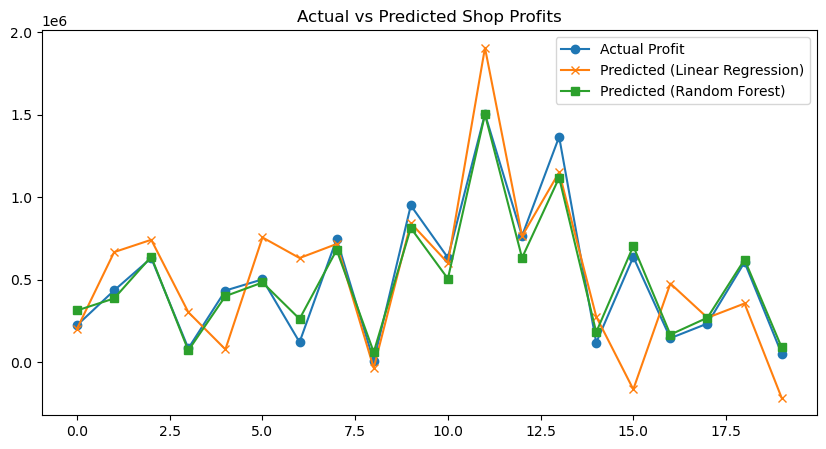

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Step 1: Load Dataset
df = pd.read_csv(r"C:\Users\rohit\Downloads\sales.csv")
df.head()

# Step 2: Feature Engineering
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
df["Delivery_Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

# Step 3: Features & Target
X = df[["Region", "Country", "Item Type", "Sales Channel", 
        "Order Priority", "Units Sold", "Unit Price", "Unit Cost", "Delivery_Days"]]
y = df["Total Profit"]

# Step 4: Preprocessing
categorical_features = ["Region", "Country", "Item Type", "Sales Channel", "Order Priority"]
numeric_features = ["Units Sold", "Unit Price", "Unit Cost", "Delivery_Days"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features)
    ]
)

# Step 5: ML Pipelines
linreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=100, random_state=42))
])

# Step 6: Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 7: Train Models
linreg_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# Step 8: Predictions
y_pred_lin = linreg_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)

# Step 9: Evaluation
print("Linear Regression R²:", r2_score(y_test, y_pred_lin))
print("Random Forest R²:", r2_score(y_test, y_pred_rf))

# Step 10: Visualization
plt.figure(figsize=(10,5))
plt.plot(y_test.values[:50], label="Actual Profit", marker='o')
plt.plot(y_pred_lin[:50], label="Predicted (Linear Regression)", marker='x')
plt.plot(y_pred_rf[:50], label="Predicted (Random Forest)", marker='s')
plt.legend()
plt.title("Actual vs Predicted Shop Profits")
plt.show()

